## Classification et analyse des bien immobiliers dans le nord

In [42]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

dataset = pd.read_csv("./data/tmp/in-preprocessed_df.csv", encoding="utf-8", low_memory=False)

# Encoder la variable cible (type_local) : fit_transform apprend le dictionnaire ET l'applique
label_encoder = LabelEncoder()
dataset["type_local_encode"] = label_encoder.fit_transform(dataset["type_local"])

print("Dictionnaire d'encodage :")
for i, classe in enumerate(label_encoder.classes_):
    print(f" - {classe} -> {i}")

#Features :  surface, nombre de pièces, prix, localisation
#Cible = type_local (encodée)
features = ["surface_reelle_bati", "nombre_pieces_principales", "valeur_fonciere", "longitude", "latitude"]
X = dataset[features]
y = dataset["type_local_encode"]

# Affichage des dimensions
print(f"Nombre d'échantillons : {X.shape[0]}")
print(f"Nombre de caractéristiques (features) : {X.shape[1]}")


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)


Dictionnaire d'encodage :
 - Appartement -> 0
 - Maison -> 1
Nombre d'échantillons : 64280
Nombre de caractéristiques (features) : 5
(51424, 5) (12856, 5)


In [43]:
from sklearn.tree import DecisionTreeClassifier

# class_weight='balanced' compense le déséquilibre Maison (~78%) / Appartement (~22%)
tree_model = DecisionTreeClassifier(max_depth=10, class_weight='balanced', random_state=42)

# Entraînement du modèle (Construction de l'arbre)
tree_model.fit(X_train, y_train)

print("Modèle d'Arbre de Décision construit avec succès.")


Modèle d'Arbre de Décision construit avec succès.


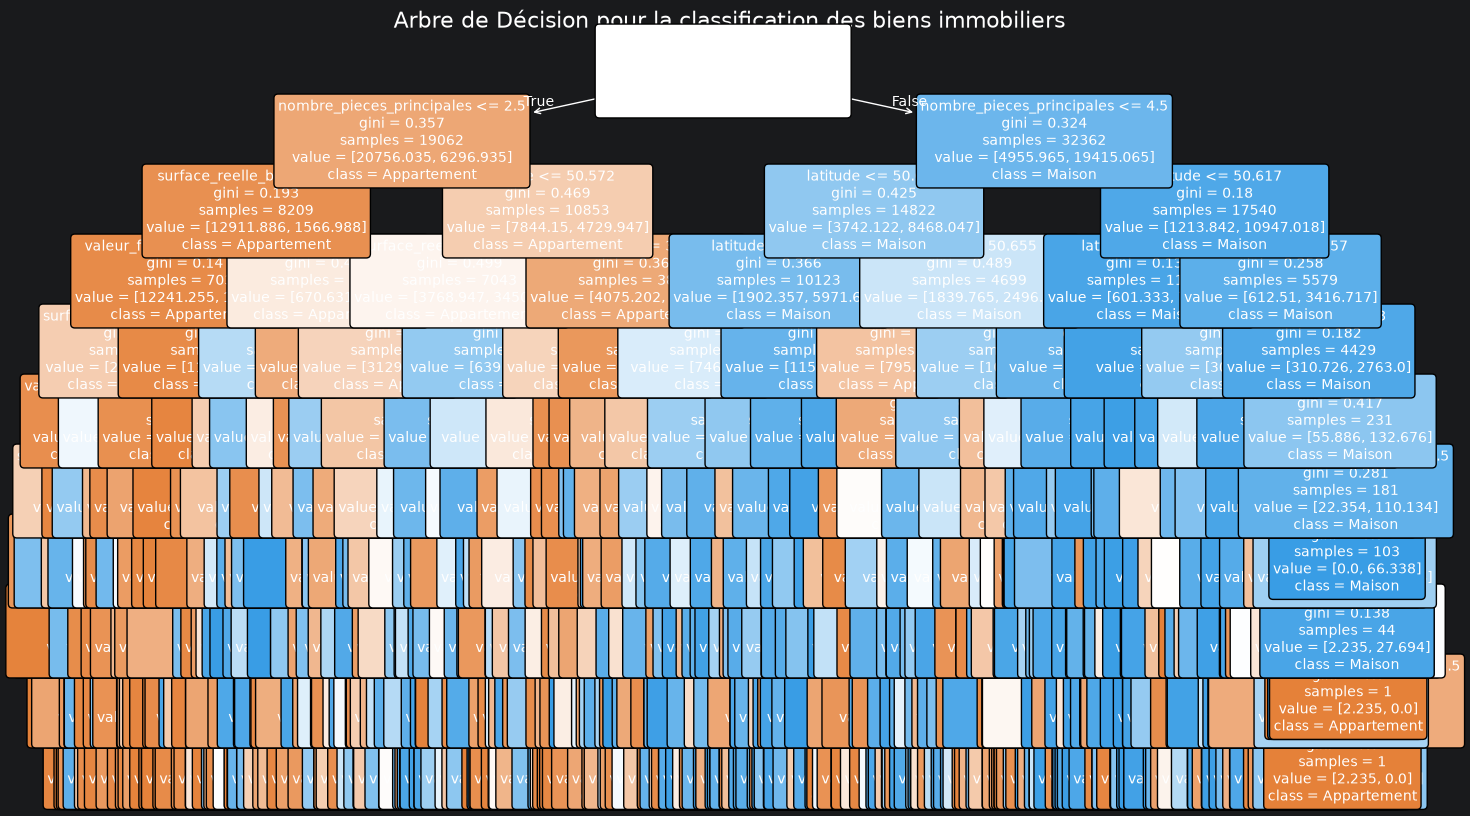

In [44]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 10))

plot_tree(tree_model,
          feature_names=list(X.columns),        # Noms des 5 features
          class_names=list(label_encoder.classes_),  # Noms des 2 classes (Appartement, Maison)
          filled=True,                       # Colorer les nœuds selon la classe majoritaire
          rounded=True,                      # Arrondir les bords des nœuds
          fontsize=10)                       # Taille de la police

plt.title('Arbre de Décision pour la classification des biens immobiliers', fontsize=16)
plt.show()

Exactitude de l'arbre de décision : 84.23%

Classe réelle Maison (9980 biens) :
  Vrais positifs (TP) : 8383 (84.00%)
  Faux négatifs  (FN) : 1597 (16.00%)
Classe réelle Appartement (2876 biens) :
  Vrais négatifs (TN) : 2445 (85.01%)
  Faux positifs  (FP) : 431 (14.99%)


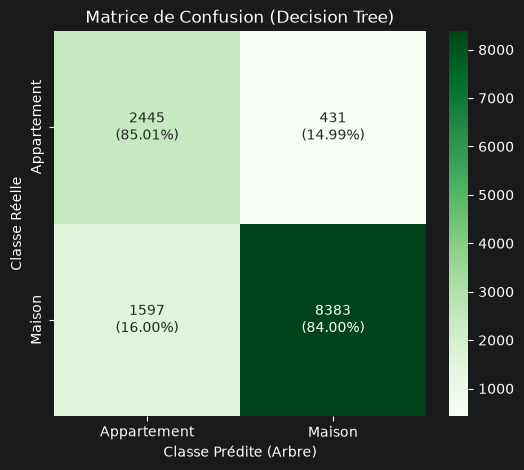

In [45]:
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns

# Prédictions sur l'ensemble de test
y_pred = tree_model.predict(X_test)

# Exactitude
accuracy = accuracy_score(y_test, y_pred)
print(f"Exactitude de l'arbre de décision : {accuracy * 100:.2f}%")

# Matrice de confusion
conf_matrix = confusion_matrix(y_test, y_pred)

# Pourcentages par classe réelle (chaque ligne = 100%)
conf_pct = conf_matrix / conf_matrix.sum(axis=1, keepdims=True) * 100

# Classe positive = 2e classe (Maison), classe négative = 1re classe (Appartement)
# On utilise label_encoder.classes_ pour retrouver les vrais noms au lieu de 0/1
negative_class, positive_class = label_encoder.classes_
tn, fp, fn, tp = conf_matrix.ravel()
tn_pct, fp_pct, fn_pct, tp_pct = conf_pct.ravel()

print(f"\nClasse réelle {positive_class} ({tp + fn} biens) :")
print(f"  Vrais positifs (TP) : {tp} ({tp_pct:.2f}%)")
print(f"  Faux négatifs  (FN) : {fn} ({fn_pct:.2f}%)")
print(f"Classe réelle {negative_class} ({tn + fp} biens) :")
print(f"  Vrais négatifs (TN) : {tn} ({tn_pct:.2f}%)")
print(f"  Faux positifs  (FP) : {fp} ({fp_pct:.2f}%)")

# Annotations : effectif + pourcentage de la classe réelle
labels = np.array([[f"{conf_matrix[i, j]}\n({conf_pct[i, j]:.2f}%)" for j in range(2)] for i in range(2)])

plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=labels, fmt='', cmap='Greens',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.xlabel('Classe Prédite (Arbre)')
plt.ylabel('Classe Réelle')
plt.title('Matrice de Confusion (Decision Tree)')
plt.show()

--- Importance des Caractéristiques ---
             Caractéristique  Importance
1  nombre_pieces_principales    0.572966
4                   latitude    0.168406
3                  longitude    0.137375
0        surface_reelle_bati    0.066189
2            valeur_fonciere    0.055064


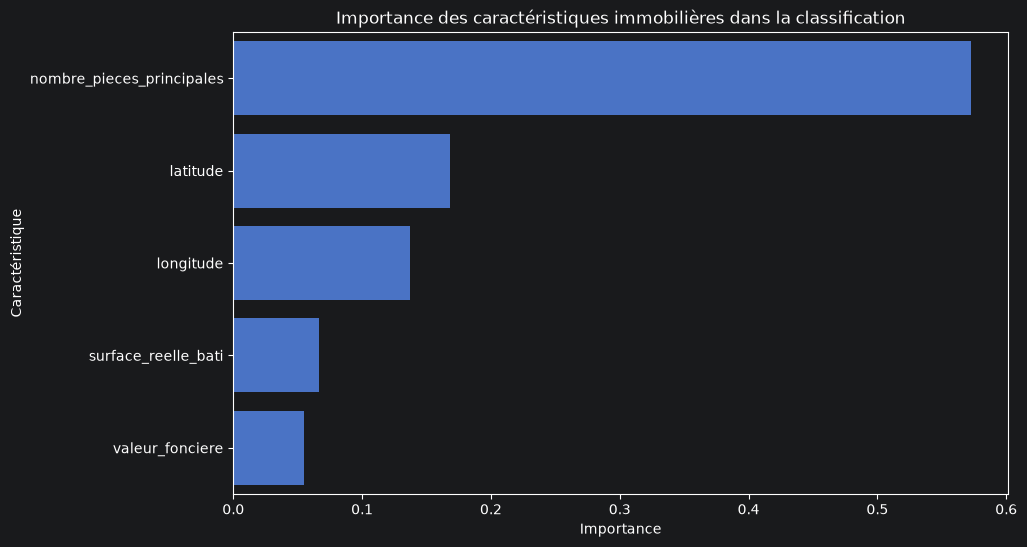

In [46]:
import pandas as pd

# Récupération de l'importance des features calculée par l'arbre
importances = tree_model.feature_importances_

# Création d'un DataFrame pour un affichage propre
feature_imp_df = pd.DataFrame({
    'Caractéristique': list(X.columns),
    'Importance': importances
})

# Tri par importance décroissante
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False)

print("--- Importance des Caractéristiques ---")
print(feature_imp_df.head(5)) # Afficher le Top 5

# Visualisation optionnelle (Bar plot)
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Caractéristique', data=feature_imp_df)
plt.title('Importance des caractéristiques immobilières dans la classification')
plt.show()

In [47]:
# Nouveaux biens, avec les mêmes noms de colonnes que lors de l'entraînement
new_properties = pd.DataFrame({
    "surface_reelle_bati":       [35,      55,      72,      28,      120,     95,      150,     85,      65,      45],
    "nombre_pieces_principales": [1,       3,       3,       1,       5,       4,       6,       4,       3,       2],
    "valeur_fonciere":           [95000,   130000,  210000,  80000,   250000,  160000,  320000,  140000,  175000,  110000],
    "longitude":                 [3.06,    3.07,    3.04,    3.06,    2.90,    3.20,    2.60,    2.95,    3.05,    3.01],
    "latitude":                  [50.63,   50.64,   50.62,   50.63,   50.40,   50.35,   50.50,   50.45,   50.65,   50.60],
})

# Résultat attendu pour chaque cas (à comparer avec la prédiction du modèle)
expected = [
    "Appartement",  # 1. Studio lillois
    "Appartement",  # 2. T3 classique en centre-ville
    "Appartement",  # 3. T3 spacieux, prix élevé, Lille
    "Appartement",  # 4. Très petit studio, petit prix
    "Maison",       # 5. Grande maison de campagne
    "Maison",       # 6. Maison familiale 4 pièces
    "Maison",       # 7. Très grande maison, 6 pièces
    "Maison",       # 8. Maison standard, périphérie
    "Appartement",  # 9. Cas ambigu : 65 m², 3 pièces, Lille
    "Appartement",  # 10. T2 en centre-ville
]

# 1. Le modèle prédit les numéros de classes (0 / 1)
predictions_numeriques = tree_model.predict(new_properties)
print(f"Prédictions brutes du modèle : {predictions_numeriques}")

# 2. On inverse l'encodage pour retrouver le texte
predicted_types = label_encoder.inverse_transform(predictions_numeriques)

print("\n--- Résultats des cas de test ---")
for i, (pred, attendu) in enumerate(zip(predicted_types, expected)):
    statut = "OK" if pred == attendu else "ÉCART"
    print(f"Bien {i+1} classé automatiquement dans : {pred.upper():<12} (attendu : {attendu:<12}) [{statut}]")

nb_ok = sum(p == a for p, a in zip(predicted_types, expected))
print(f"\n{nb_ok}/{len(expected)} prédictions conformes aux attentes")


Prédictions brutes du modèle : [0 0 0 0 1 1 1 1 0 0]

--- Résultats des cas de test ---
Bien 1 classé automatiquement dans : APPARTEMENT  (attendu : Appartement ) [OK]
Bien 2 classé automatiquement dans : APPARTEMENT  (attendu : Appartement ) [OK]
Bien 3 classé automatiquement dans : APPARTEMENT  (attendu : Appartement ) [OK]
Bien 4 classé automatiquement dans : APPARTEMENT  (attendu : Appartement ) [OK]
Bien 5 classé automatiquement dans : MAISON       (attendu : Maison      ) [OK]
Bien 6 classé automatiquement dans : MAISON       (attendu : Maison      ) [OK]
Bien 7 classé automatiquement dans : MAISON       (attendu : Maison      ) [OK]
Bien 8 classé automatiquement dans : MAISON       (attendu : Maison      ) [OK]
Bien 9 classé automatiquement dans : APPARTEMENT  (attendu : Appartement ) [OK]
Bien 10 classé automatiquement dans : APPARTEMENT  (attendu : Appartement ) [OK]

10/10 prédictions conformes aux attentes


In [ ]:
import joblib
from pathlib import Path

# Sauvegarde du modèle entraîné + de l'encodeur pour l'application Streamlit (src/app.py)
Path("./models").mkdir(exist_ok=True)
joblib.dump(
    {"model": tree_model, "label_encoder": label_encoder, "features": features},
    "./models/tree_model.joblib",
)
print("Modèle sauvegardé dans ./models/tree_model.joblib")